# Couette prediction evaluation

Load a trained pressure→velocity model, generate predictions on the validation set, and compare against the ground truth.

Statistics computed:
1. Mean & std velocity per component along y — original vs predicted vs difference


In [3]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

device = "cuda"
keys = 'u', 'v', 'w', 'p_total'


def extract(real, keys):
    with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
        data = []
        for k in keys:
            data.append(np.array(f[real][k]))
        return np.stack(data, axis=1)


# --- same realizations / splits as the training notebook ---
realizations = ['R13', 'R14', 'R15', 'R18', 'R19', 'R21', 'R22', 'R23', 'R26', 'R28', 'R3', 'R4', 'R5']
samplings = {real: np.s_[:-1:5000 // 300] if real in ["R3", "R4", "R5"] else np.s_[:] for real in realizations}

raw_d = {real: extract(real, keys)[samplings[real]] for real in realizations}
all_data = np.concatenate(list(raw_d.values()), axis=0)

val_realizations = ["R18", "R5"]
test_realizations = ["R3", "R14"]
train_realizations = [real for real in realizations if real not in val_realizations + test_realizations]
val_npds = np.concatenate([raw_d[r] for r in val_realizations])

print("val data shape:", val_npds.shape)

# domain coordinates
with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
    y = np.array(f["y"])
    x = np.array(f["x"])
    z = np.array(f["z"])

print("y shape:", y.shape)


val data shape: (600, 4, 24, 33, 24)
y shape: (33,)


In [4]:
# --- Load the trained model ---
# TODO: update S3 path to your actual checkpoint
S3_BUCKET = "simulations"
S3_ENDPOINT = "http://localhost:8333"
S3_CHECKPOINT = "flow_models/couette/width-study_lw32_c32_b5_w0/final.pt"

import s3fs, io
fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url': S3_ENDPOINT})
buf = fs.cat_file(f"{S3_BUCKET}/{S3_CHECKPOINT}")
ckpt = torch.load(io.BytesIO(buf), map_location="cpu")
print("checkpoint config:", ckpt["config"])


# --- Rebuild model architecture (same M4 as framework_2.ipynb) ---
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding="same"),
            nn.SiLU(),
            nn.Conv3d(out_ch, out_ch, 3, padding="same"),
            nn.SiLU(),
        )
    def forward(self, x):
        return self.conv(x)


class M4(nn.Module):
    def __init__(self, lift_width=32, c3d=32, n_blocks=5, widen=0):
        super().__init__()
        self.D = 33
        self.c3d = c3d
        self.xd, self.zd = 24, 24

        self.pressure_encoder = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding="same"),
            nn.SiLU(),
            nn.Conv2d(8, 32, 3, padding="same"),
            nn.SiLU(),
        )

        in_lift = 32
        if widen > 0:
            self.pre_widen = nn.Sequential(
                nn.Conv2d(32, widen, 3, padding="same"),
                nn.SiLU(),
            )
            in_lift = widen

        self.lift = nn.Conv2d(in_lift, self.D * lift_width, 3, padding="same")
        self.lift_proj = (nn.Conv3d(lift_width, c3d, 1)
                          if lift_width != c3d else nn.Identity())
        self.conv_blocks = nn.Sequential(*[ConvBlock(c3d, c3d) for _ in range(n_blocks)])
        self.output = nn.Conv3d(c3d, 3, 3, padding="same")

    def forward(self, pressure):
        x = self.pressure_encoder(pressure)
        if hasattr(self, "pre_widen"):
            x = self.pre_widen(x)
        x = self.lift(x)
        x = x.reshape(-1, self.lift.out_channels // self.D, self.xd, self.D, self.zd)
        x = self.lift_proj(x)
        x = self.conv_blocks(x)
        x = self.output(x)
        return x


# instantiate from checkpoint config
cfg = ckpt["config"]
widen = 0  # TODO: set to actual widen value if >0
model = M4(lift_width=cfg["lift_width"], c3d=cfg["c3d"],
           n_blocks=cfg["n_blocks"], widen=widen).to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"loaded model: {n_params/1e6:.2f}M params")


checkpoint config: {'lift_width': 32, 'c3d': 32, 'n_blocks': 5}
loaded model: 0.59M params


In [5]:
# --- Normalization (same as training) ---
normalization_axes = (0, 2, 4)
all_data_mean = all_data.mean(normalization_axes, keepdims=True)
all_data_std = all_data.std(normalization_axes, keepdims=True) + 1e-10

all_data_mean_gpu = torch.from_numpy(all_data_mean).to(device)
all_data_std_gpu = torch.from_numpy(all_data_std).to(device)


def normalize(data):
    return (data - all_data_mean) / all_data_std


def unnormalize_velocity_gpu(data):
    return (data * all_data_std_gpu[:, :3]) + all_data_mean_gpu[:, :3]


# --- Build the prediction dataset ---
class ValDS(Dataset):
    def __init__(self, d):
        # input: pressure (channel index 3), shape (N, 1, X, Y, Z)
        self.x = torch.from_numpy(d[:, 3:, :, 0, :]).float().to(device)
        # target: velocity (channels 0-2), shape (N, 3, X, Y, Z)
        self.y = torch.from_numpy(d[:, :3, :, :, :]).float().to(device)

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, i):
        return self.x[i], self.y[i]


val_ds = ValDS(normalize(val_npds))
batch_size = 4
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, drop_last=True)
print(f"val dataset: {len(val_ds)} samples, {len(val_dl)} batches")


val dataset: 600 samples, 150 batches


In [6]:
# --- Generate predictions ---
@torch.no_grad()
def predict_all(model, ds):
    model.eval()
    preds = []
    for x, y in ds:
        preds.append(model(x))
    return torch.cat(preds, dim=0)  # (N, 3, X, Y, Z) normalized

print("generating predictions...")
pred_norm = predict_all(model, val_dl)
print("pred shape:", pred_norm.shape)

# unnormalize predictions back to physical units
pred_phys = unnormalize_velocity_gpu(pred_norm).cpu().numpy()
# ground truth in physical units (val_npds is already in physical units)
target_phys = val_npds[:, :3, :, :, :].astype(np.float32)

print("pred_phys shape:", pred_phys.shape)
print("target_phys shape:", target_phys.shape)
print("pred range: [%.4f, %.4f]" % (pred_phys.min(), pred_phys.max()))
print("target range: [%.4f, %.4f]" % (target_phys.min(), target_phys.max()))


generating predictions...
pred shape: torch.Size([600, 3, 24, 33, 24])
pred_phys shape: (600, 3, 24, 33, 24)
target_phys shape: (600, 3, 24, 33, 24)
pred range: [-0.9433, 0.9576]
target range: [-1.0256, 1.0067]


MSE (global, all components): 2.51e-03
  u_x: 6.45e-03
  u_y: 2.79e-04
  u_z: 8.15e-04


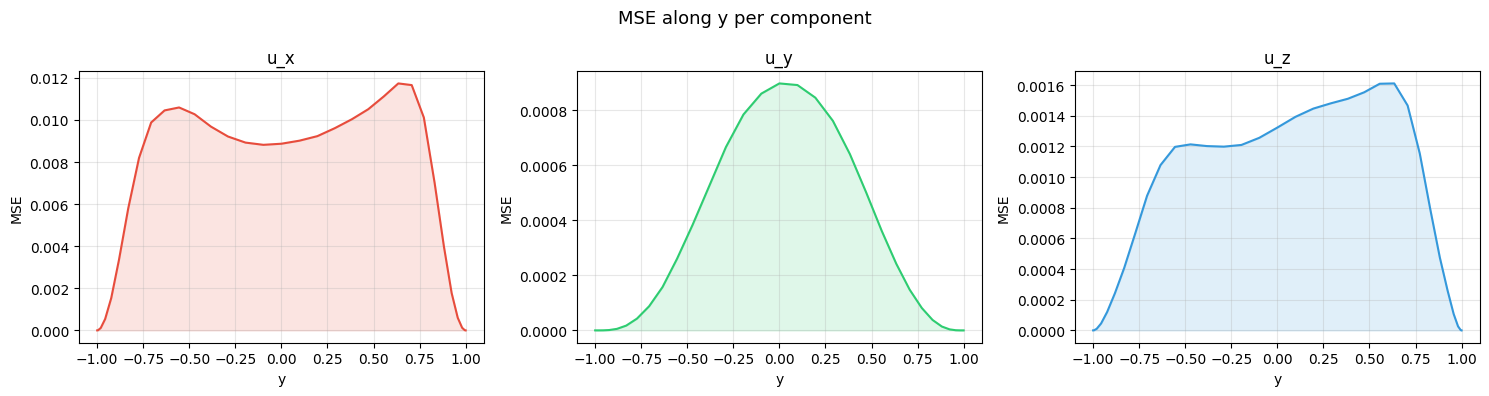

In [9]:
# =========================================================================
# MSE statistics
# =========================================================================
mse_scalar = float(((pred_phys - target_phys) ** 2).mean())
print(f"MSE (global, all components): {mse_scalar:.2e}")

# MSE per component (mean over T, X, Y, Z = axes 0,2,3,4)
mse_per_comp = ((pred_phys - target_phys) ** 2).mean(axis=(0, 2, 3, 4))  # (3,)
for c, lab in enumerate(comp_labels):
    print(f"  {lab}: {mse_per_comp[c]:.2e}")

# MSE profile along y (mean over T, X, Z = axes 0,2,4, keep Y)
mse_y = ((pred_phys - target_phys) ** 2).mean(axis=(0, 2, 4))  # (3, 33)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("MSE along y per component", fontsize=13)
colors = ['#e74c3c', '#2ecc71', '#3498db']
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    ax.plot(y, mse_y[c], color=colors[c])
    ax.fill_between(y, mse_y[c], alpha=0.15, color=colors[c])
    ax.set_title(f'{lab}')
    ax.set_xlabel('y')
    ax.set_ylabel('MSE')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Parseval check (spec.sum() / (N*X*Y*Z*var), should be 1.0):
   u_x: tgt=0.999999   pred=1.000057
   u_y: tgt=1.000001   pred=1.000002
   u_z: tgt=1.001116   pred=1.000491

annular bins: dk=1.0, kmax=24.228, n_bins=25

relative error per annulus (MSE / target energy):
   |k|~  0.5: u_x: 2.56e+00, u_y: 1.37e+12, u_z: 2.90e-01
   |k|~  1.5: u_x: 2.47e+00, u_y: 1.05e-01, u_z: 2.59e-01
   |k|~  2.5: u_x: 6.10e-01, u_y: 2.10e-02, u_z: 6.26e-02
   |k|~  3.5: u_x: 4.45e-01, u_y: 3.20e-02, u_z: 2.36e-02
   |k|~  4.5: u_x: 6.28e-02, u_y: 2.51e-02, u_z: 1.61e-02
   |k|~  5.5: u_x: 2.70e-01, u_y: 1.45e-02, u_z: 6.28e-03
   |k|~  6.5: u_x: 6.94e-02, u_y: 9.16e-03, u_z: 3.88e-03
   |k|~  7.5: u_x: 3.53e-02, u_y: 3.66e-03, u_z: 3.34e-03
   |k|~  8.5: u_x: 2.47e-02, u_y: 2.55e-03, u_z: 1.35e-03
   |k|~  9.5: u_x: 1.27e-02, u_y: 1.35e-03, u_z: 2.13e-03
   |k|~ 10.5: u_x: 9.82e-03, u_y: 1.00e-03, u_z: 1.01e-03
   |k|~ 11.5: u_x: 6.86e-03, u_y: 8.54e-04, u_z: 8.00e-04
   |k|~ 12.5: u_x: 4.07e-03, u_y: 6.

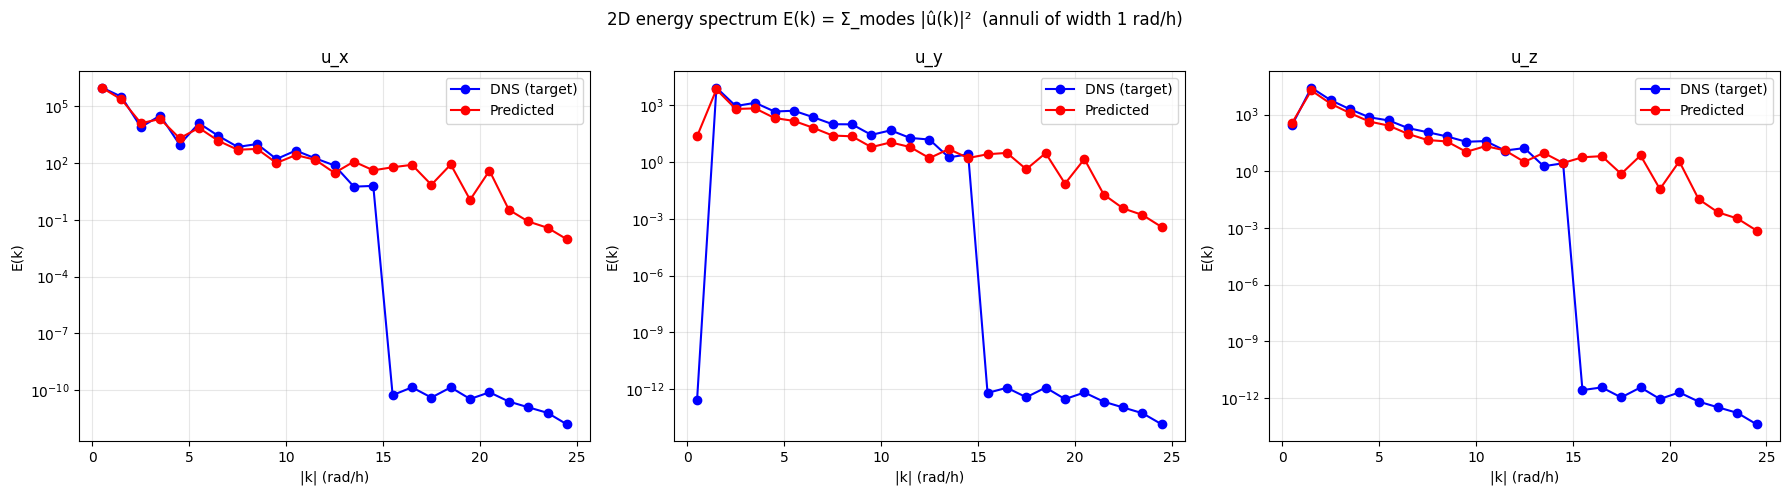

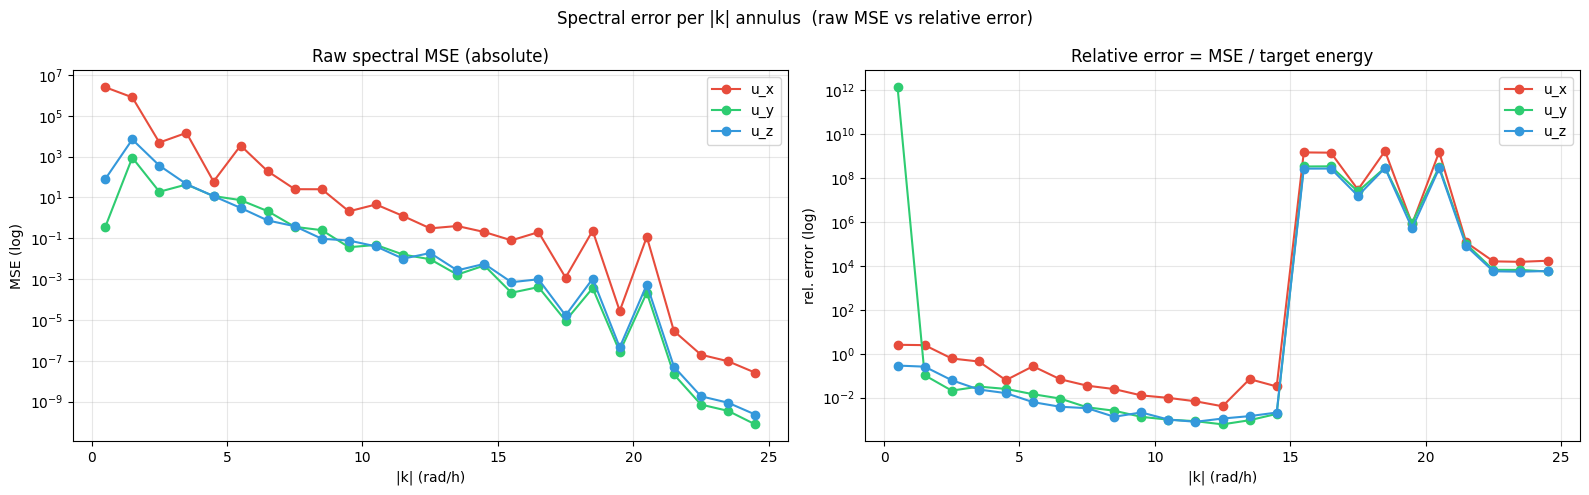

In [38]:
# =========================================================================
# 2D energy spectrum E(k) per component, binned in annuli of |k|
# =========================================================================
# Periodic directions x (Lx=1.755 pi h, 24 pts), z (Lz=1.2 pi h, 24 pts).
# y (33 pts) is non-periodic -> 2D FFT in x-z per (N, y).
# Data layout: (N=600, C=3, X=24, Y=33, Z=24)
#
# A proper 2D spectrum bins modes by wavenumber magnitude |k|=sqrt(kx^2+kz^2)
# into annuli [k, k+dk), and reports the TOTAL energy in each annulus
# (sum over all modes + N + y). This is the standard E(k) used in turbulence.

Lx, Lz = 1.755 * np.pi, 1.2 * np.pi
nx, nyy, nz = 24, 33, 24

kx = np.fft.fftfreq(nx, d=Lx / nx) * 2 * np.pi   # rad/h
kz = np.fft.fftfreq(nz, d=Lz / nz) * 2 * np.pi
KX, KZ = np.meshgrid(kx, kz, indexing="xy")       # (X, Z)
K2c = np.sqrt(KX**2 + KZ**2)                       # |k| per mode

comp_labels = ['u_x', 'u_y', 'u_z']

def energy_spectrum(field, comp):
    """Parseval-normalized 2D FFT in x-z. field (N,C,X,Y,Z) -> (N,X,Y,Z)."""
    F = np.fft.fft2(field[:, comp], axes=(1, 3))
    return (np.abs(F)**2) / (nx*nz)

tgt_spec = np.stack([energy_spectrum(target_phys, c) for c in range(3)])  # (3,N,X,Y,Z)
prd_spec = np.stack([energy_spectrum(pred_phys,   c) for c in range(3)])

# --- Parseval sanity ---
print("Parseval check (spec.sum() / (N*X*Y*Z*var), should be 1.0):")
for c, lab in enumerate(comp_labels):
    r_t = tgt_spec[c].sum() / (target_phys[:, c].size * target_phys[:, c].var())
    r_p = prd_spec[c].sum() / (pred_phys[:, c].size * pred_phys[:, c].var())
    print(f"   {lab}: tgt={r_t:.6f}   pred={r_p:.6f}")

# --- annular bins in |k| ---
dk = 1.0
kmax = K2c.max()
k_edges = np.arange(0.0, kmax + dk, dk)          # 0,1,2,...
k_centers = 0.5 * (k_edges[:-1] + k_edges[1:])
n_bins = len(k_centers)
print(f"\nannular bins: dk={dk}, kmax={kmax:.3f}, n_bins={n_bins}")

# mask per annulus
ann_masks = [(K2c >= k_edges[i]) & (K2c < k_edges[i+1]) for i in range(n_bins)]

# =========================================================================
# Per-annulus total energy (sum over modes, N, y) — the 2D spectrum E(k)
# =========================================================================
tgt_E = np.zeros((n_bins, 3))
prd_E = np.zeros((n_bins, 3))
mse_E = np.zeros((n_bins, 3))

for c in range(3):
    for i, m in enumerate(ann_masks):
        # (N,X,Y,Z) masked -> sum over (X,Z) -> (N,Y); sum over N too -> scalar (total energy)
        t_total = (tgt_spec[c] * m[None, :, None, :]).sum(axis=(1, 3)).sum()
        p_total = (prd_spec[c] * m[None, :, None, :]).sum(axis=(1, 3)).sum()
        tgt_E[i, c] = t_total
        prd_E[i, c] = p_total
        mse_E[i, c] = (((prd_spec[c] - tgt_spec[c]) * m[None, :, None, :])**2).sum()

# keep only non-empty annuli for plotting
nonempty = np.array([m.sum() > 0 for m in ann_masks])
k_centers_p = k_centers[nonempty]
tgt_E_p = tgt_E[nonempty]
prd_E_p = prd_E[nonempty]
mse_E_p = mse_E[nonempty]

# =========================================================================
# Plot 1: 2D spectrum E(k) per component (semilog)
# =========================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("2D energy spectrum E(k) = Σ_modes |û(k)|²  (annuli of width 1 rad/h)", fontsize=12)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    ax.semilogy(k_centers_p, tgt_E_p[:, c], 'b-o', label='DNS (target)', lw=1.5)
    ax.semilogy(k_centers_p, prd_E_p[:, c], 'r-o', label='Predicted', lw=1.5)
    ax.set_title(f'{lab}')
    ax.set_xlabel('|k| (rad/h)'); ax.set_ylabel('E(k)')
    ax.grid(alpha=0.3, which='both'); ax.legend()
plt.tight_layout()
plt.show()

# =========================================================================
# Plot 2: RELATIVE spectral error per annulus  (MSE / target energy)
#   = (sum |pred-tgt|^2) / (sum |tgt|^2)  within each annulus
#   -> "how wrong the model is relative to the energy actually present",
#      removes the low-|k| magnitude bias of the raw MSE.
# =========================================================================
with np.errstate(divide='ignore', invalid='ignore'):
    rel_err = np.where(tgt_E_p > 0, mse_E_p / np.maximum(tgt_E_p, 1e-300), np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Spectral error per |k| annulus  (raw MSE vs relative error)", fontsize=12)

# raw MSE (the "low-freq fails more" view)
ax = axes[0]
for c, (lab, col) in enumerate(zip(comp_labels, ['#e74c3c', '#2ecc71', '#3498db'])):
    ax.semilogy(k_centers_p, mse_E_p[:, c], '-o', color=col, label=lab, lw=1.5)
ax.set_title('Raw spectral MSE (absolute)'); ax.set_xlabel('|k| (rad/h)'); ax.set_ylabel('MSE (log)')
ax.grid(alpha=0.3, which='both'); ax.legend()

# relative error (the "high-freq fails more" view)
ax = axes[1]
for c, (lab, col) in enumerate(zip(comp_labels, ['#e74c3c', '#2ecc71', '#3498db'])):
    ax.semilogy(k_centers_p, rel_err[:, c], '-o', color=col, label=lab, lw=1.5)
ax.set_title('Relative error = MSE / target energy'); ax.set_xlabel('|k| (rad/h)'); ax.set_ylabel('rel. error (log)')
ax.grid(alpha=0.3, which='both'); ax.legend()
plt.tight_layout()
plt.show()

print("\nrelative error per annulus (MSE / target energy):")
for i in range(len(k_centers_p)):
    row = ", ".join(f"{lab}: {rel_err[i,c]:.2e}" if rel_err[i,c] == rel_err[i,c] else f"{lab}: nan"
                    for c, lab in enumerate(comp_labels))
    print(f"   |k|~{k_centers_p[i]:5.1f}: {row}")

# =========================================================================
# Print: E(k) per component
# =========================================================================
print("\nE(k) per annulus (tgt / pred):")
for i in range(len(k_centers_p)):
    row = ", ".join(f"{lab}: {tgt_E_p[i,c]:.3e}/{prd_E_p[i,c]:.3e}"
                    for c, lab in enumerate(comp_labels))
    print(f"   |k|~{k_centers_p[i]:5.1f}: {row}")


RMS (target / pred):
  u_x: 0.16172 / 0.13604
  u_y: 0.02391 / 0.01973
  u_z: 0.04898 / 0.04041

max |diff| RMS per component: u_x=4.346e-02, u_y=9.790e-03, u_z=1.763e-02
max |diff| Reynolds stress: $\langle u'v'\rangle$=4.610e+02, $\langle u'w'\rangle$=4.212e+02, $\langle v'w'\rangle$=1.874e+01


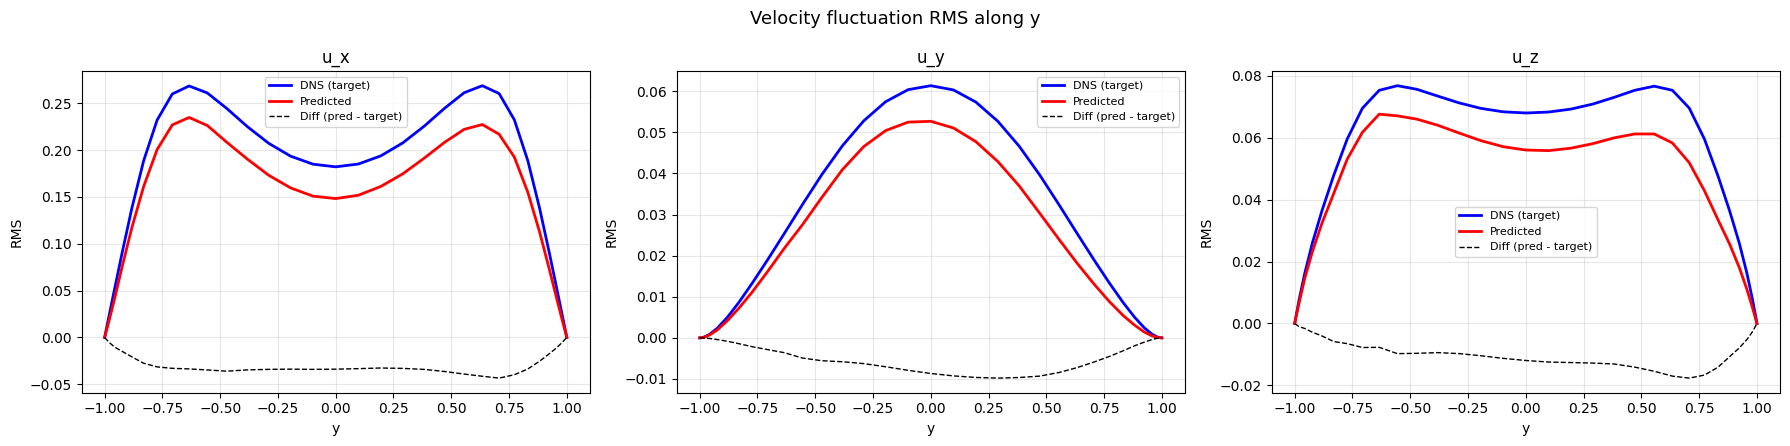

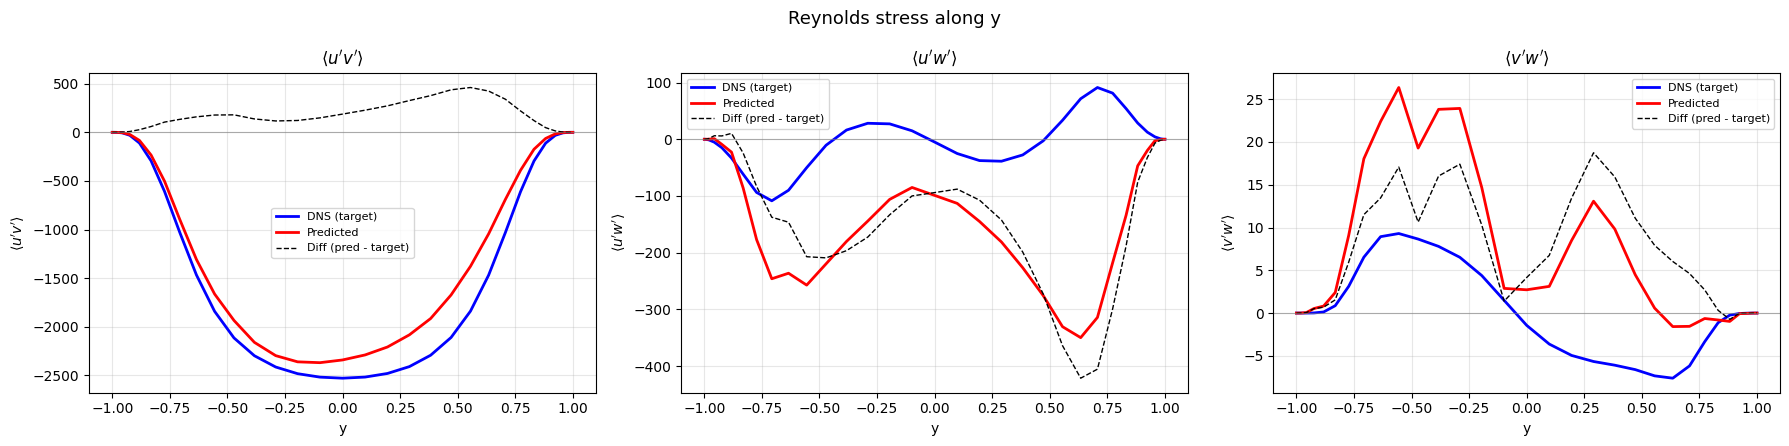

In [31]:
# =========================================================================
# RMS fluctuations & Reynolds stress  (original vs predicted vs difference)
# =========================================================================
# Fluctuation: subtract the mean over T (0), x (2), z (4) — keep y profile
comp_labels = ['u_x', 'u_y', 'u_z']

def rms_and_reynolds(field):
    """field: (N, C, X, Y, Z). Returns rms (C, Y) and R (C, C, Y)."""
    u_fluc = field - field.mean(axis=(0, 2, 4), keepdims=True)   # (N,C,X,Y,Z)
    rms = np.sqrt((u_fluc ** 2).mean(axis=(0, 2, 4)))            # (C, Y)
    R = np.einsum("n c i y z, n d i y z -> c d y", u_fluc, u_fluc)  # (C,C,Y)
    return rms, R

rms_t, R_t = rms_and_reynolds(target_phys)
rms_p, R_p = rms_and_reynolds(pred_phys)

print("RMS (target / pred):")
for c, lab in enumerate(comp_labels):
    print(f"  {lab}: {rms_t[c].mean():.5f} / {rms_p[c].mean():.5f}")

# --- Plot 1: RMS per component ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("Velocity fluctuation RMS along y", fontsize=13)
for c, lab in enumerate(comp_labels):
    ax = axes[c]
    ax.plot(y, rms_t[c], 'b-', label='DNS (target)', lw=2)
    ax.plot(y, rms_p[c], 'r-', label='Predicted', lw=2)
    ax.plot(y, rms_p[c] - rms_t[c], 'k--', label='Diff (pred - target)', lw=1)
    ax.set_title(f'{lab}')
    ax.set_xlabel('y'); ax.set_ylabel('RMS')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Plot 2: Reynolds shear stresses ---
stress_pairs = [
    (0, 1, r"$\langle u'v'\rangle$"),
    (0, 2, r"$\langle u'w'\rangle$"),
    (1, 2, r"$\langle v'w'\rangle$"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("Reynolds stress along y", fontsize=13)
for ax, (i, j, lab) in zip(axes, stress_pairs):
    ax.plot(y, R_t[i, j], 'b-', label='DNS (target)', lw=2)
    ax.plot(y, R_p[i, j], 'r-', label='Predicted', lw=2)
    ax.plot(y, R_p[i, j] - R_t[i, j], 'k--', label='Diff (pred - target)', lw=1)
    ax.set_title(lab)
    ax.set_xlabel('y'); ax.set_ylabel(lab)
    ax.axhline(0, color='gray', lw=0.8, alpha=0.6)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- print max abs errors ---
print("\nmax |diff| RMS per component:", ", ".join(f"{lab}={np.abs(rms_p[c]-rms_t[c]).max():.3e}" for c, lab in enumerate(comp_labels)))
print("max |diff| Reynolds stress:",
      ", ".join(f"{lab}={np.abs(R_p[i,j]-R_t[i,j]).max():.3e}" for i, j, lab in stress_pairs))


PDF shape statistics (target / pred) at buffer layer y=-0.83:
  u_x: skew  -0.023 / -0.224   kurtosis(excess) -1.034 / -0.955
  u_y: skew  -0.691 / -0.916   kurtosis(excess) +5.007 / +5.083
  u_z: skew  +0.018 / +0.056   kurtosis(excess) +0.828 / +0.043


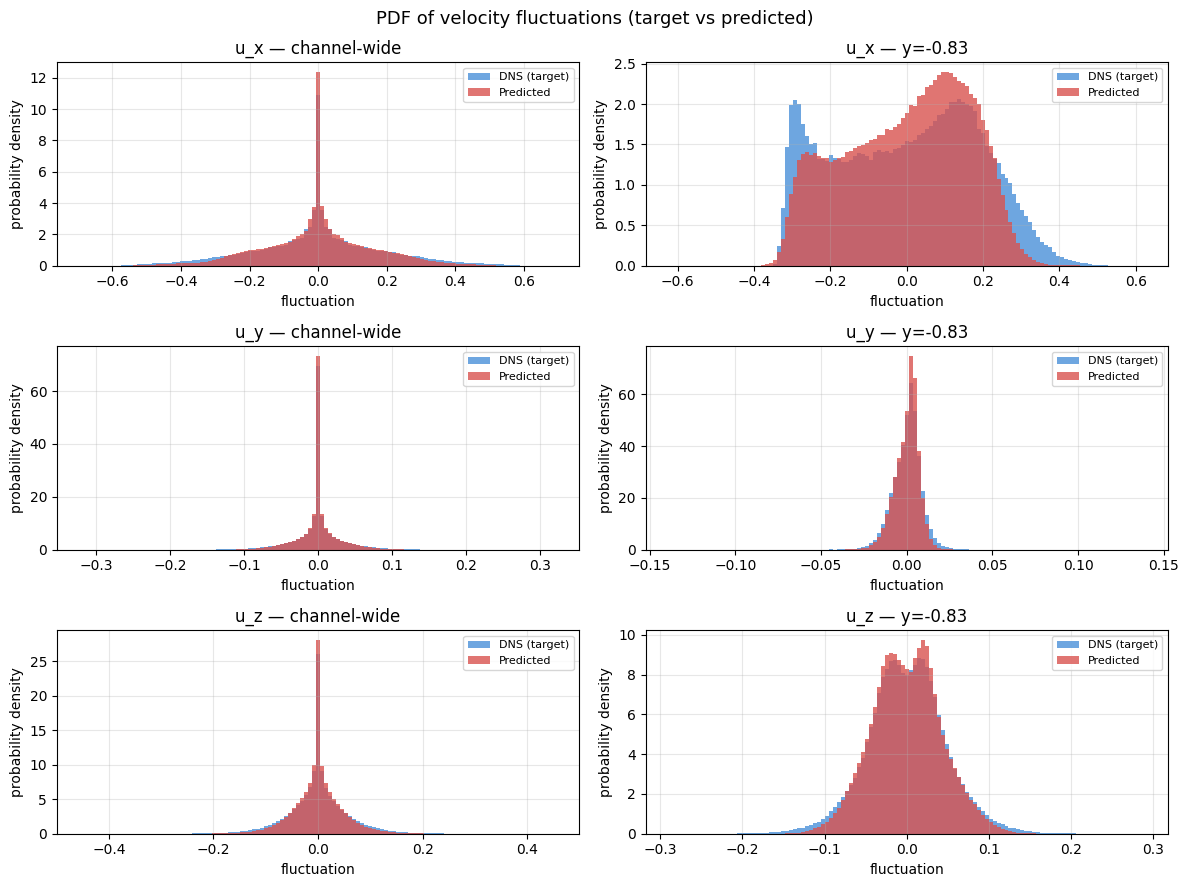

In [32]:
# =========================================================================
# PDF of velocity fluctuations  (original vs predicted vs difference)
# =========================================================================
# u_fluc already defined in the RMS/Reynolds cell: (N, C, X, Y, Z)
def fluct(field):
    return field - field.mean(axis=(0, 2, 4), keepdims=True)

u_fluc_t = fluct(target_phys)
u_fluc_p = fluct(pred_phys)

comp_labels = ['u_x', 'u_y', 'u_z']
y_idx_center = nyy // 2          # channel center
y_idx_wall = 6                  # buffer layer, away from wall

fig, axes = plt.subplots(3, 2, figsize=(12, 9))
fig.suptitle("PDF of velocity fluctuations (target vs predicted)", fontsize=13)

for c, lab in enumerate(comp_labels):
    # --- channel-wide PDF ---
    ax = axes[c, 0]
    v_t = u_fluc_t[:, c].ravel()
    v_p = u_fluc_p[:, c].ravel()
    lim = max(np.abs(v_t).max(), np.abs(v_p).max()) * 1.05
    bins = np.linspace(-lim, lim, 120)
    ax.hist(v_t, bins=bins, density=True, color='#4a90d9', alpha=0.8, label='DNS (target)')
    ax.hist(v_p, bins=bins, density=True, color='#d9534f', alpha=0.8, label='Predicted')
    ax.set_title(f'{lab} — channel-wide')
    ax.set_xlabel('fluctuation'); ax.set_ylabel('probability density')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

    # --- PDF at a fixed y (buffer layer) ---
    ax = axes[c, 1]
    vt = u_fluc_t[:, c, :, y_idx_wall, :].ravel()
    vp = u_fluc_p[:, c, :, y_idx_wall, :].ravel()
    lim = max(np.abs(vt).max(), np.abs(vp).max()) * 1.05
    bins = np.linspace(-lim, lim, 120)
    ax.hist(vt, bins=bins, density=True, color='#4a90d9', alpha=0.8, label='DNS (target)')
    ax.hist(vp, bins=bins, density=True, color='#d9534f', alpha=0.8, label='Predicted')
    ax.set_title(f'{lab} — y={y[y_idx_wall]:.2f}')
    ax.set_xlabel('fluctuation'); ax.set_ylabel('probability density')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# --- skewness / kurtosis summary (non-gaussianity) ---
from scipy.stats import skew, kurtosis
print("PDF shape statistics (target / pred) at buffer layer y=%.2f:" % y[y_idx_wall])
for c, lab in enumerate(comp_labels):
    vt = u_fluc_t[:, c, :, y_idx_wall, :].ravel()
    vp = u_fluc_p[:, c, :, y_idx_wall, :].ravel()
    print(f"  {lab}: skew  {skew(vt):+.3f} / {skew(vp):+.3f}   "
          f"kurtosis(excess) {kurtosis(vt):+.3f} / {kurtosis(vp):+.3f}")


mean_pred shape: (3, 33)
std_pred shape: (3, 33)


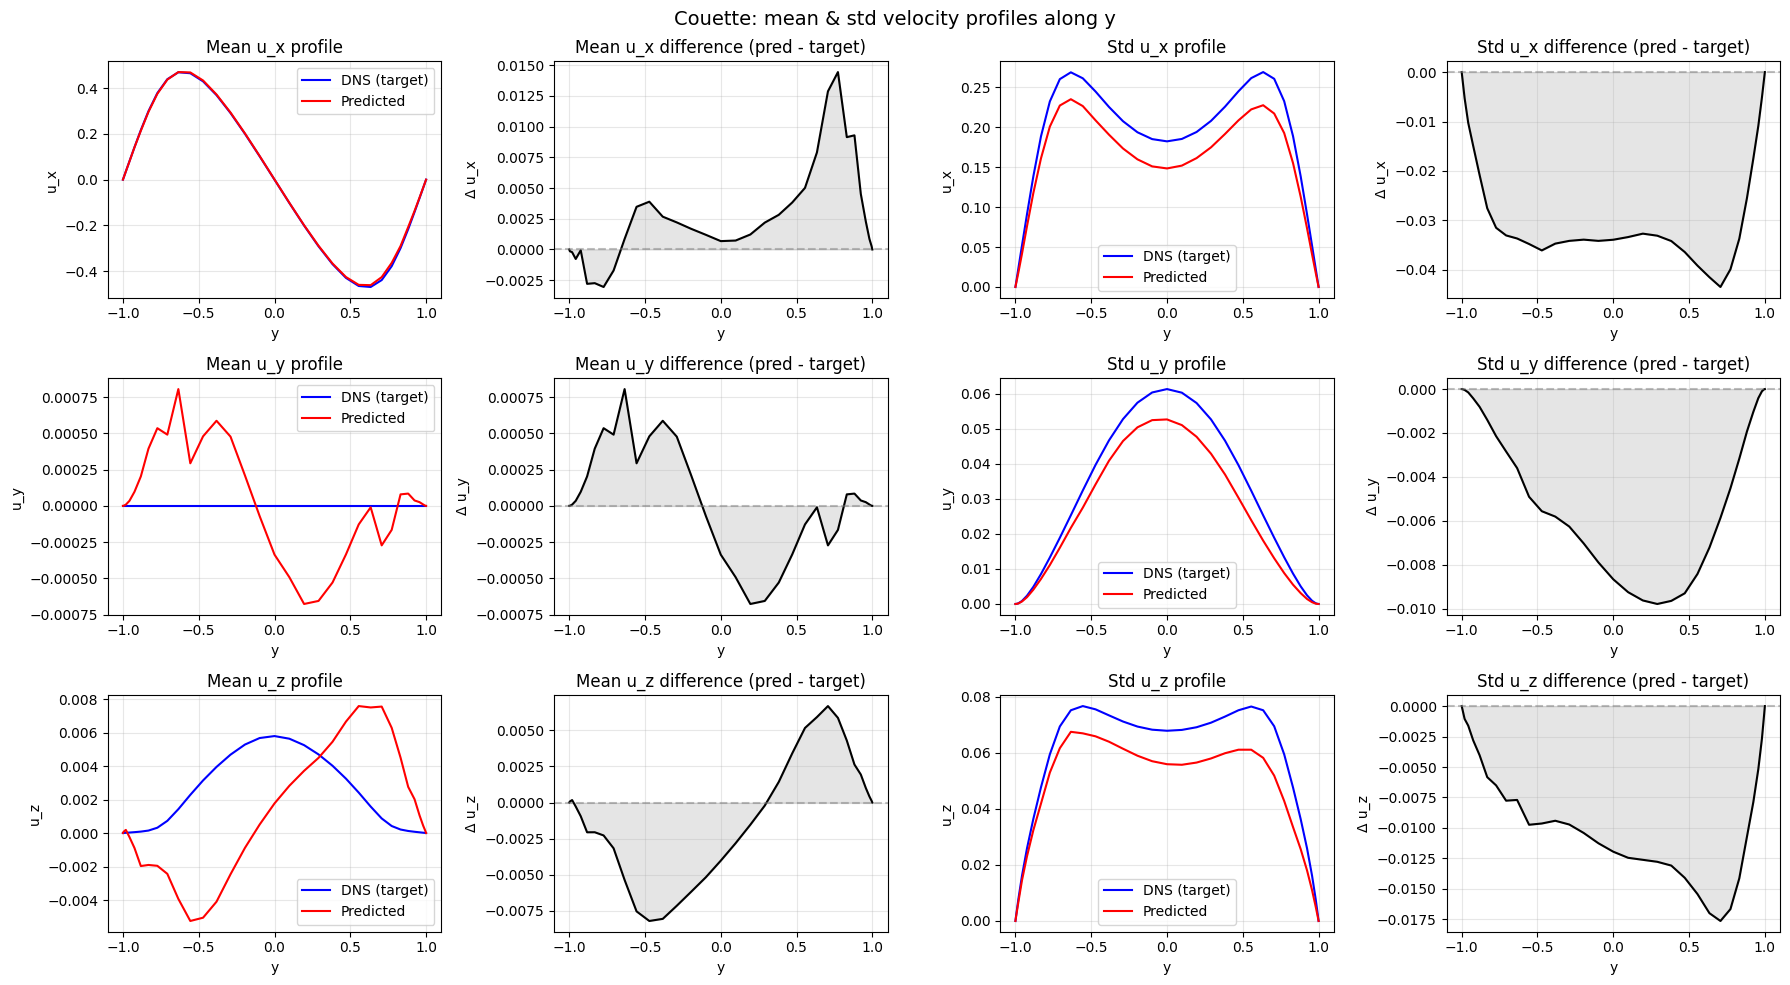

In [7]:
# =========================================================================
# Statistics: mean & std velocity per component along y
# =========================================================================
# Shapes: pred_phys / target_phys are (N, 3, X=24, Y=33, Z=24)
# We average over T (axis 0), X (axis 2), Z (axis 4) -> (3, 33)
# std over T, X, Z -> (3, 33)

comp_labels = ['u_x', 'u_y', 'u_z']

# mean profile along y: average over time, x, z
mean_pred = pred_phys.mean(axis=(0, 2, 4))    # (3, 33)
mean_tgt = target_phys.mean(axis=(0, 2, 4))   # (3, 33)

# std profile along y: std over time, x, z
std_pred = pred_phys.std(axis=(0, 2, 4))      # (3, 33)
std_tgt = target_phys.std(axis=(0, 2, 4))     # (3, 33)

print("mean_pred shape:", mean_pred.shape)
print("std_pred shape:", std_pred.shape)

# --- Plot: one row per component (u_x, u_y, u_z) ---
# Row layout: 2 cols -> [original vs predicted]  [difference]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
fig.suptitle("Couette: mean & std velocity profiles along y", fontsize=14, y=0.98)

for c, lab in enumerate(comp_labels):
    # --- mean ---
    ax = axes[c, 0]
    ax.plot(y, mean_tgt[c], 'b-', label='DNS (target)')
    ax.plot(y, mean_pred[c], 'r-', label='Predicted')
    ax.set_title(f'Mean {lab} profile')
    ax.set_xlabel('y')
    ax.set_ylabel(lab)
    ax.legend(loc='best')
    ax.grid(alpha=0.3)

    # --- mean difference ---
    ax = axes[c, 1]
    diff_mean = mean_pred[c] - mean_tgt[c]
    ax.plot(y, diff_mean, 'k-')
    ax.fill_between(y, diff_mean, alpha=0.2, color='gray')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(f'Mean {lab} difference (pred - target)')
    ax.set_xlabel('y')
    ax.set_ylabel('Δ ' + lab)
    ax.grid(alpha=0.3)

    # --- std ---
    ax = axes[c, 2]
    ax.plot(y, std_tgt[c], 'b-', label='DNS (target)')
    ax.plot(y, std_pred[c], 'r-', label='Predicted')
    ax.set_title(f'Std {lab} profile')
    ax.set_xlabel('y')
    ax.set_ylabel(lab)
    ax.legend(loc='best')
    ax.grid(alpha=0.3)

    # --- std difference ---
    ax = axes[c, 3]
    diff_std = std_pred[c] - std_tgt[c]
    ax.plot(y, diff_std, 'k-')
    ax.fill_between(y, diff_std, alpha=0.2, color='gray')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(f'Std {lab} difference (pred - target)')
    ax.set_xlabel('y')
    ax.set_ylabel('Δ ' + lab)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
